# 02 · The two models — logistic regression from scratch, and a random forest

**Read first:** `01_theory/02_ml_basics.md`, `01_theory/04_models.md`

1. sigmoid and log-loss — the numbers of theory §4.1–4.2
2. **logistic regression written from scratch** with gradient descent ("error × input"), checked against
   scikit-learn
3. why scaling matters for gradient descent
4. the weights *are* the explanation
5. Gini impurity by hand, then a random forest with feature importance and a grid search

In [1]:
import csv
import math
import re
from collections import Counter
from pathlib import Path
from urllib.parse import urlparse

import numpy as np
import matplotlib.pyplot as plt

from url_features import extract, FEATURE_NAMES      # the extractor built in notebook 01

urls, y = [], []
with open(Path("../data/phishing_urls.csv"), encoding="utf-8") as f:
    for row in csv.DictReader(f):
        urls.append(row["URL"]); y.append(1 if row["Label"] == "bad" else 0)
X, y = np.array([extract(u) for u in urls]), np.array(y)

rng = np.random.default_rng(42)
perm = rng.permutation(len(y))
a, b = int(.70 * len(y)), int(.85 * len(y))
tr, va, te = perm[:a], perm[a:b], perm[b:]
np.savez("../data/_split.npz", tr=tr, va=va, te=te)       # notebook 03 reuses the same split
print("train / validation / test:", len(tr), len(va), len(te))

train / validation / test: 8000 1715 1715


## 1. Sigmoid and log-loss — the numbers from the theory chapter

In [2]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))
for z in (-5, 0, 5, 0.35, 1.15, -2.40):
    print(f"sigmoid({z:+.2f}) = {sigmoid(z):.3f}")
logloss = lambda truth, p: -math.log(p) if truth == 1 else -math.log(1 - p)
print("phishing, p=0.76 ->", round(logloss(1, .76), 2), "   phishing, p=0.10 ->", round(logloss(1, .10), 2),
      "   (confident and wrong is punished hard)")

sigmoid(-5.00) = 0.007
sigmoid(+0.00) = 0.500
sigmoid(+5.00) = 0.993
sigmoid(+0.35) = 0.587
sigmoid(+1.15) = 0.760
sigmoid(-2.40) = 0.083
phishing, p=0.76 -> 0.27    phishing, p=0.10 -> 2.3    (confident and wrong is punished hard)


## 2. Logistic regression from scratch

For every weight: $\partial\text{loss}/\partial w_i = (p - \text{truth})\cdot x_i$ — "error times input",
averaged over the training rows. Plus the L2 brake $\frac{1}{C}\,w$.

validation accuracy (from scratch): 0.779


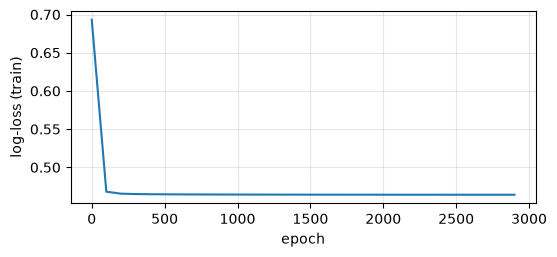

In [3]:
class LogisticRegressionScratch:
    def __init__(self, C=1.0, lr=0.5, epochs=3000):
        self.C, self.lr, self.epochs = C, lr, epochs

    def fit(self, X, y):
        n, d = X.shape
        self.w, self.b, self.history = np.zeros(d), 0.0, []
        for epoch in range(self.epochs):
            p = sigmoid(X @ self.w + self.b)
            error = p - y                                        # (p - truth) for every row
            grad_w = X.T @ error / n + self.w / (self.C * n)     # error x input, averaged, + L2
            grad_b = error.mean()
            self.w -= self.lr * grad_w
            self.b -= self.lr * grad_b
            if epoch % 100 == 0:
                eps = 1e-12
                self.history.append(-np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps)))
        return self

    def predict_proba(self, X):
        return sigmoid(X @ self.w + self.b)

# StandardScaler, fitted on TRAINING rows only
mean, std = X[tr].mean(0), X[tr].std(0)
std[std == 0] = 1
Z = (X - mean) / std

model = LogisticRegressionScratch(C=1.0).fit(Z[tr], y[tr])
acc = np.mean((model.predict_proba(Z[va]) >= .5) == y[va])
print(f"validation accuracy (from scratch): {acc:.3f}")
plt.figure(figsize=(6, 2.5)); plt.plot(np.arange(len(model.history)) * 100, model.history)
plt.xlabel("epoch"); plt.ylabel("log-loss (train)"); plt.grid(alpha=.3); plt.show()

### Same as scikit-learn?

scikit-learn minimises the same loss with a smarter optimiser. Its L2 term is `0.5·|w|²` added to the **sum**
of losses with weight C — which is exactly our `w / (C·n)` on the mean. So the weights should agree closely.

In [4]:
from sklearn.linear_model import LogisticRegression
sk = LogisticRegression(C=1.0, max_iter=5000).fit(Z[tr], y[tr])
print("largest weight difference:", np.abs(sk.coef_[0] - model.w).max().round(4))
print("predictions that differ on validation:", np.sum((sk.predict_proba(Z[va])[:, 1] >= .5) != (model.predict_proba(Z[va]) >= .5)))

largest weight difference: 0.1331
predictions that differ on validation: 0


## 3. Why scale? Train on the raw features

In [5]:
raw = LogisticRegressionScratch(C=1.0, lr=1e-4, epochs=3000).fit(X[tr], y[tr])
print(f"raw features, after the same 3000 steps: validation accuracy {np.mean((raw.predict_proba(X[va]) >= .5) == y[va]):.3f}")

raw features, after the same 3000 steps: validation accuracy 0.679


With `url_length` around 50 and booleans at 0/1, any learning rate is wrong for one of them: big enough for
the booleans makes the length explode, small enough for the length leaves the booleans frozen.

## 4. The weights are the explanation

In [6]:
for i in np.argsort(-np.abs(model.w))[:8]:
    print(f"{FEATURE_NAMES[i]:24s} {model.w[i]:+.2f}")

url = "http://paypal.com.secure-login.xyz/verify/account?id=7731"
z = (np.array(extract(url)) - mean) / std
contrib = model.w * z
print(f"\n{url}\nP(phishing) = {model.predict_proba(z[None])[0]:.3f}   because:")
for i in np.argsort(-np.abs(contrib))[:5]:
    print(f"   {FEATURE_NAMES[i]:24s} value {extract(url)[i]:6.2f}  ({z[i]:+.1f} std)   pushes {contrib[i]:+.2f}")

url_length               +1.09
suspicious_word_count    +0.97
num_hyphens              -0.89
host_length              +0.85
has_at_symbol            +0.84
num_subdomains           -0.80
digit_ratio              +0.77
num_slashes              +0.67

http://paypal.com.secure-login.xyz/verify/account?id=7731
P(phishing) = 1.000   because:
   suspicious_word_count    value   5.00  (+7.0 std)   pushes +6.71
   suspicious_tld           value   1.00  (+14.7 std)   pushes +3.65
   brand_in_subdomain       value   1.00  (+4.4 std)   pushes +1.35
   num_subdomains           value   2.00  (+1.1 std)   pushes -0.89
   host_length              value  27.00  (+0.6 std)   pushes +0.49


## 5. Trees: Gini impurity by hand (theory §4.5)

In [7]:
gini = lambda counts: 1 - sum((c / sum(counts)) ** 2 for c in counts)
print("root 5/5:", gini([5, 5]))
print("split on has_https: 0.5*gini([4,1]) + 0.5*gini([1,4]) =", round(.5 * gini([4, 1]) + .5 * gini([1, 4]), 2), "-> gain 0.18")
print("split on num_dots : 0.6*gini([3,3]) + 0.4*gini([2,2]) =", round(.6 * gini([3, 3]) + .4 * gini([2, 2]), 2), "-> gain 0")

root 5/5: 0.5
split on has_https: 0.5*gini([4,1]) + 0.5*gini([1,4]) = 0.32 -> gain 0.18
split on num_dots : 0.6*gini([3,3]) + 0.4*gini([2,2]) = 0.5 -> gain 0


## 6. The random forest, tuned with GridSearchCV (5-fold, on the training rows only)

best settings: {'max_depth': 20, 'min_samples_leaf': 1}  CV F1 0.861
validation accuracy: forest 0.869   logistic 0.779


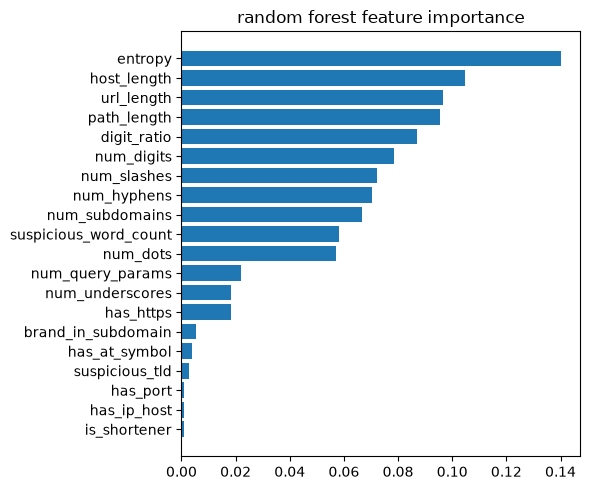

['../data/_models.joblib']

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
                    {"max_depth": [None, 10, 20], "min_samples_leaf": [1, 3]}, cv=5, scoring="f1")
grid.fit(X[tr], y[tr])
forest = grid.best_estimator_
print("best settings:", grid.best_params_, f" CV F1 {grid.best_score_:.3f}")
print(f"validation accuracy: forest {forest.score(X[va], y[va]):.3f}   logistic {acc:.3f}")

imp = forest.feature_importances_
order = np.argsort(imp)
plt.figure(figsize=(6, 5)); plt.barh(np.array(FEATURE_NAMES)[order], imp[order])
plt.title("random forest feature importance"); plt.tight_layout(); plt.show()

import joblib
joblib.dump({"forest": forest, "logistic_w": model.w, "logistic_b": model.b, "mean": mean, "std": std},
            "../data/_models.joblib")

The forest is stronger because it can learn interactions ("many dots matter only without HTTPS") that a linear
model cannot. The price: one prediction is harder to explain. Your project trains both and keeps the better one.

## ✍️ Try it yourself

1. Change `C` to 0.01 and 100 in the scratch model. What happens to the size of the weights? To accuracy?
2. Compute by hand the log-loss for p = 0.30 and p = 0.95 when the URL is phishing. Explain the difference.
3. A single tree with `max_depth=None, min_samples_leaf=1`: compare train and validation accuracy. Why the gap?

Then solve exercises 6–9 in `03_exercises/`.